# Réplica de Grigorescu, Alistar y Lincaru (2025)

Réplica de:
  Grigorescu, A., Alistar, T. V. y Lincaru, C. (2025). Digital Skills, Ethics, and Integrity:
  The Impact of Risky Internet Use, a Multivariate and Spatial Approach to Understanding NEET
  Vulnerability. Systems, 13(8), 649. https://doi.org/10.3390/systems13080649

Datos: la Tabla A1 del propio paper (28 países europeos, 28 indicadores de Eurostat),
transcrita en datos_grigorescu_tablaA1.csv. El paper usó SPSS; aquí todo se hace en Python
reproduciendo los mismos algoritmos.

Se replica, en el orden del paper:
1. Estadísticos descriptivos                      (Tabla A2)
2. Pruebas de normalidad K-S y Shapiro-Wilk       (Tabla 2)
3. Correlaciones de Spearman                      (sección 5.1)
4. Componentes principales, Varimax y Promax      (sección 5.2, Tablas 3, A3 y A4)
5. Regresión logística con los factores           (sección 5.3)
6. Diagnósticos por país que el paper mapea       (sección 5.4, Figuras 3 a 5)
7. Árbol de decisión CHAID                        (sección 5.5, Apéndice C)

Lo que el paper dice mal, o es mejorable, va en comentarios OBS-n junto al código:
- OBS-1  Datos: periodo, edades y países descritos de forma contradictoria.
- OBS-2  Las pruebas de normalidad no deciden nada en este análisis.
- OBS-3  Las correlaciones de Spearman del texto no salen de sus propios datos.
- OBS-4  PCA con 24 variables y 28 casos.
- OBS-5  El Apéndice B se titula "Varimax" pero una columna es de Promax.
- OBS-6  La logística descrita (GLM con proporciones) no es la que se reporta.
- OBS-7  El modelo logístico no es significativo y aun así se concluye a su favor.
- OBS-8  Apalancamiento promedio mal calculado; Hosmer-Lemeshow con 28 casos.
- OBS-9  Mapas hechos en ArcGIS: aquí se entregan los valores por país.
- OBS-10 CHAID: la tabla resumen del texto contradice al Apéndice C.
- OBS-11 CHAID: los grupos de países del texto no corresponden a los datos.
- OBS-12 CHAID: la variable IMAP se describe de tres formas distintas.
- OBS-13 CHAID: dicotomizar por la mediana y probar 24 predictores con 28 casos.
- OBS-14 CHAID: el riesgo por validación cruzada depende del sorteo y el publicado es optimista.

Transparencia: no se ajustó ningún dato ni se buscó ninguna semilla para acercar cifras. La
única elección hecha mirando el resultado publicado es el agrupamiento de Hosmer-Lemeshow, y
está avisada en el código. El archivo resumen_replica_vs_paper.csv lista cada cifra comparada.

**Uso:** ejecutar las celdas en orden con `datos_grigorescu_tablaA1.csv` en la misma carpeta que este notebook. Las tablas y figuras se guardan en `resultados_grigorescu/`. La validación cruzada del árbol (sección 7) tarda alrededor de un minuto.

## Librerías y funciones auxiliares

In [1]:
import itertools
import math
import os
import warnings

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.diagnostic import lilliefors

warnings.filterwarnings("ignore")
AQUI = os.getcwd()   # el notebook y datos_grigorescu_tablaA1.csv deben estar en la misma carpeta
SALIDA = os.path.join(AQUI, "resultados_grigorescu")
AZUL, FONDO, TEXTO, TEXTO2, REJILLA = "#2a78d6", "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"

NEET = ["NEET2020", "NEET2021", "NEET2022", "NEET2023"]
# Las 24 variables digitales, en el orden de la Tabla A4 del paper
DIGITALES = ["2020CHAT1", "2021CHAT1", "2023CHAT1", "2024CHAT1", "2020SNET", "2021SNET", "2023SNET",
             "2024SNET", "IDay2020", "IDay2021", "IDay2022", "IDay2023", "IDay2024", "IMAP2020",
             "IMAP2021", "IMAP2023", "I_DSK2_2021_LW", "I_DSK2_2021_N", "I_DSK2_2021_LM",
             "I_DSK2_2021_X", "I_DSK2_2023_LW", "I_DSK2_2023_N", "I_DSK2_2023_LM", "I_DSK2_2023_X"]

RESUMEN = []      # filas (análisis, indicador, paper, réplica, coincide)


def anotar(analisis, indicador, paper, replica, tol):
    """Guarda una comparación. 'tol' es la mitad del último decimal que publica el paper."""
    ok = abs(float(replica) - float(paper)) <= tol + 1e-12
    RESUMEN.append({"análisis": analisis, "indicador": indicador, "paper": paper,
                    "réplica": float(replica), "coincide": "sí" if ok else "NO"})
    return ok


def titulo(t):
    print("\n" + "=" * 96 + f"\n{t}\n" + "=" * 96)

os.makedirs(SALIDA, exist_ok=True)
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')
g = lambda nombre: os.path.join(SALIDA, nombre)

## 0. Datos
Tabla A1 del paper: 28 países × 28 indicadores.

In [2]:
# =============================================================================================
# 0. DATOS
# =============================================================================================
def cargar():
    # OBS-1. DATOS. El paper se contradice al describirlos: el resumen dice "2000-2023", la
    # metodología "2000-2024" y luego "2020-2023", y la tabla trae indicadores de 2020 a 2024.
    # Define la tasa de ninis para jóvenes de 15 a 24 años y en el Apéndice A dice que los
    # indicadores son de jóvenes de 16 a 34. Habla de "28 países europeos" como si fuera la UE,
    # pero la tabla incluye Noruega, Serbia y Turquía y NO incluye a Francia ni a Irlanda.
    # Tampoco publica el archivo de datos: dice que "son de Eurostat". Por suerte la Tabla A1
    # imprime las 28 filas completas, y de ahí se transcribieron. Eurostat revisa sus series,
    # así que para replicar hay que usar la tabla del paper, no una descarga nueva.
    d = pd.read_csv(os.path.join(AQUI, "datos_grigorescu_tablaA1.csv")).set_index("codigo")
    assert d.shape == (28, 29), d.shape
    return d

In [3]:
d = cargar()
d.head()

,pais,NEET2020,NEET2021,NEET2022,NEET2023,2020SNET,2021SNET,2023SNET,2024SNET,2020CHAT1,2021CHAT1,2023CHAT1,2024CHAT1,IDay2020,IDay2021,IDay2022,IDay2023,IDay2024,IMAP2020,IMAP2021,IMAP2023,I_DSK2_2021_LW,I_DSK2_2023_LW,I_DSK2_2021_N,I_DSK2_2023_N,I_DSK2_2021_LM,I_DSK2_2023_LM,I_DSK2_2021_X,I_DSK2_2023_X
codigo,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
BE,Belgium,9.2000,7.4000,6.6000,6.7000,94.6100,89.2100,90.6600,87.8500,83.5500,82.5900,84.2600,85.8700,95.9700,96.5600,95.8800,96.4400,97.5200,56.7500,60.4400,63.8300,18.6500,20.5700,9.2100,7.5700,2.9000,1.6800,1.2700,0.3200
BG,Bulgaria,14.4000,13.9000,12.3000,11.4000,81.3100,86.8000,88.0900,85.3500,76.9300,82.2100,86.2100,81.3100,90.1800,91.7300,94.4000,93.2400,93.1300,42.2900,47.0500,50.3400,19.5400,19.9100,11.4600,11.7900,6.6500,4.7800,4.2300,3.9100
CZ,Czechia,6.6000,6.5000,8.0000,6.3000,95.0900,95.3600,98.1800,99.3300,95.1200,97.2200,98.8500,97.8100,97.1800,98.2200,98.7100,99.2300,99.0700,74.1800,73.9400,81.5000,12.0600,5.5000,3.0500,1.5700,0.7600,0.0000,0.1900,0.0000
DK,Denmark,7.5000,7.1000,6.7000,7.1000,96.7700,97.1200,98.5900,97.8300,97.6100,97.5600,96.7800,97.1900,99.2700,98.2800,98.9800,97.8400,98.4300,83.2200,81.9700,80.9500,15.1700,15.9800,3.0400,2.8300,0.0000,0.5700,0.2200,1.0200
DE,Germany,7.4000,7.8000,7.0000,7.5000,88.5400,77.9500,73.0600,83.9900,94.9500,77.6200,77.6400,90.2400,97.6400,95.4900,95.0900,95.1600,96.1400,82.6500,63.0800,66.4800,25.1800,25.6100,9.3500,10.4100,3.7700,3.4700,1.5400,1.5900


## 1. Estadísticos descriptivos (Tabla A2)
Asimetría y curtosis con corrección muestral (G1 y G2), como SPSS.

In [4]:
# =============================================================================================
# 1. DESCRIPTIVOS (Tabla A2)
# =============================================================================================
A2 = {  # variable: (suma, media, DE, asimetría, curtosis) tal como los publica el paper
    "NEET2020": (300.4, 10.729, 4.9320, 1.828, 4.909), "NEET2021": (296.7, 10.596, 4.7385, 1.239, 2.058),
    "NEET2022": (272.1, 9.718, 4.2374, 1.640, 4.040), "NEET2023": (264.7, 9.454, 3.8104, 1.567, 3.979),
    "2020SNET": (2532.81, 90.4575, 5.82060, -0.902, -0.408), "2020CHAT1": (2554.20, 91.2214, 7.63292, -1.644, 3.644),
    "2021SNET": (2544.54, 90.8764, 5.32230, -1.103, 0.375), "2021CHAT1": (2560.05, 91.4304, 6.85302, -0.930, 0.177),
    "2023SNET": (2558.13, 91.3618, 6.18967, -1.413, 1.986), "2023CHAT1": (2591.58, 92.5564, 6.89640, -0.997, -0.119),
    "2024SNET": (2557.56, 91.3414, 4.67254, -0.151, -0.718), "2024CHAT1": (2585.99, 92.3568, 5.96558, -1.074, 0.447),
    "IDay2020": (2704.48, 96.5886, 3.47202, -1.658, 2.324), "IDay2021": (2715.83, 96.9939, 2.22461, -1.064, 0.257),
    "IDay2022": (2725.82, 97.3507, 1.87078, -0.744, -0.567), "IDay2023": (2742.10, 97.9321, 1.69048, -1.217, 1.242),
    "IDay2024": (2746.61, 98.0932, 1.84114, -1.432, 1.524), "IMAP2020": (1791.41, 63.98, 14.12, 0.076, -1.034),
    "IMAP2021": (1832.36, 65.4414, 12.71700, 0.043, -0.803), "IMAP2023": (1869.11, 66.7539, 14.51852, -0.076, -0.294),
    "I_DSK2_2021_LW": (450.46, 16.0879, 6.01996, -0.268, -1.146), "I_DSK2_2021_N": (155.11, 5.5396, 3.53941, 0.726, -0.522),
    "I_DSK2_2021_LM": (51.77, 1.8489, 2.13540, 1.477, 1.784), "I_DSK2_2021_X": (27.33, 0.9761, 1.47247, 2.222, 5.131),
    "I_DSK2_2023_LW": (474.30, 16.9393, 8.46311, 1.174, 3.682), "I_DSK2_2023_N": (167.29, 5.9746, 4.16636, 0.652, -0.405),
    "I_DSK2_2023_LM": (58.89, 2.1032, 1.98368, 0.967, 0.745), "I_DSK2_2023_X": (27.30, 0.9750, 1.27323, 1.706, 2.637),
}


def descriptivos(d):
    filas = []
    for v, (s, m, sd, sk, ku) in A2.items():
        x = d[v]
        r = {"variable": v, "N": len(x), "mínimo": x.min(), "máximo": x.max(), "suma": x.sum(),
             "media": x.mean(), "DE": x.std(ddof=1), "varianza": x.var(ddof=1),
             # SPSS usa las fórmulas corregidas por tamaño de muestra (G1 y G2)
             "asimetría": stats.skew(x, bias=False), "curtosis": stats.kurtosis(x, bias=False),
             "suma paper": s, "media paper": m, "DE paper": sd, "asimetría paper": sk, "curtosis paper": ku}
        filas.append(r)
        dec = lambda p: 0.5 * 10 ** -(len(str(p).split(".")[1]) if "." in str(p) else 0)
        anotar("1. Descriptivos (Tabla A2)", f"{v}: suma", s, r["suma"], 0.005)
        anotar("1. Descriptivos (Tabla A2)", f"{v}: media", m, r["media"], dec(m))
        anotar("1. Descriptivos (Tabla A2)", f"{v}: DE", sd, r["DE"], dec(sd))
        anotar("1. Descriptivos (Tabla A2)", f"{v}: asimetría", sk, r["asimetría"], 0.0005)
        anotar("1. Descriptivos (Tabla A2)", f"{v}: curtosis", ku, r["curtosis"], 0.0005)
    return pd.DataFrame(filas).set_index("variable")

In [5]:
t = descriptivos(d)
t.to_csv(g("1_descriptivos.csv"))
t[["suma", "suma paper", "media", "media paper", "DE", "DE paper", "asimetría", "asimetría paper", "curtosis", "curtosis paper"]]

,suma,suma paper,media,media paper,DE,DE paper,asimetría,asimetría paper,curtosis,curtosis paper
variable,,,,,,,,,,
NEET2020,300.4000,300.4000,10.7286,10.7290,4.9320,4.9320,1.8281,1.8280,4.9094,4.9090
NEET2021,296.7000,296.7000,10.5964,10.5960,4.7385,4.7385,1.2390,1.2390,2.0580,2.0580
NEET2022,272.1000,272.1000,9.7179,9.7180,4.2374,4.2374,1.6398,1.6400,4.0398,4.0400
NEET2023,264.7000,264.7000,9.4536,9.4540,3.8104,3.8104,1.5673,1.5670,3.9786,3.9790
2020SNET,"2,532.8100","2,532.8100",90.4575,90.4575,5.8206,5.8206,-0.9020,-0.9020,-0.4084,-0.4080
2020CHAT1,"2,554.2000","2,554.2000",91.2214,91.2214,7.6329,7.6329,-1.6437,-1.6440,3.6443,3.6440
2021SNET,"2,544.5400","2,544.5400",90.8764,90.8764,5.3223,5.3223,-1.1034,-1.1030,0.3746,0.3750
2021CHAT1,"2,560.0500","2,560.0500",91.4304,91.4304,6.8530,6.8530,-0.9300,-0.9300,0.1773,0.1770
2023SNET,"2,558.1300","2,558.1300",91.3618,91.3618,6.1897,6.1897,-1.4133,-1.4130,1.9859,1.9860


## 2. Normalidad: Kolmogorov-Smirnov (Lilliefors) y Shapiro-Wilk (Tabla 2)

In [6]:
# =============================================================================================
# 2. NORMALIDAD (Tabla 2)
# =============================================================================================
T2 = {  # variable: (K-S estadístico, K-S sig., S-W estadístico, S-W sig.)
    "NEET2020": (0.162, 0.058, 0.853, 0.001), "NEET2021": (0.191, 0.010, 0.904, 0.015),
    "NEET2022": (0.158, 0.070, 0.871, 0.003), "NEET2023": (0.168, 0.043, 0.889, 0.006),
    "2020SNET": (0.171, 0.034, 0.873, 0.003), "2020CHAT1": (0.145, 0.137, 0.856, 0.001),
    "2021SNET": (0.156, 0.077, 0.881, 0.004), "2021CHAT1": (0.158, 0.071, 0.907, 0.017),
    "2023SNET": (0.177, 0.025, 0.874, 0.003), "2023CHAT1": (0.170, 0.037, 0.858, 0.001),
    "2024SNET": (0.109, 0.200, 0.969, 0.563), "2024CHAT1": (0.186, 0.014, 0.893, 0.008),
    "IDay2020": (0.215, 0.002, 0.795, 0.000), "IDay2021": (0.161, 0.060, 0.881, 0.004),
    "IDay2022": (0.200, 0.006, 0.911, 0.021), "IDay2023": (0.182, 0.019, 0.889, 0.006),
    "IDay2024": (0.196, 0.007, 0.842, 0.001), "IMAP2020": (0.111, 0.200, 0.948, 0.178),
    "IMAP2021": (0.076, 0.200, 0.972, 0.637), "IMAP2023": (0.098, 0.200, 0.977, 0.779),
    "I_DSK2_2021_LW": (0.130, 0.200, 0.944, 0.141), "I_DSK2_2021_N": (0.219, 0.001, 0.905, 0.015),
    "I_DSK2_2021_LM": (0.193, 0.009, 0.820, 0.000), "I_DSK2_2021_X": (0.254, 0.000, 0.700, 0.000),
    "I_DSK2_2023_LW": (0.109, 0.200, 0.916, 0.027), "I_DSK2_2023_N": (0.121, 0.200, 0.936, 0.085),
    "I_DSK2_2023_LM": (0.145, 0.135, 0.894, 0.008), "I_DSK2_2023_X": (0.222, 0.001, 0.776, 0.000),
}


def normalidad(d):
    # OBS-2. El paper usa estas pruebas para elegir Spearman en vez de Pearson, lo cual es
    # razonable, pero luego aplica PCA (que parte de correlaciones de Pearson) y regresión
    # logística, que no dependen de esa decisión. Con 28 casos, además, la prueba tiene poca
    # potencia: "no rechazar" la normalidad no significa que la variable sea normal.
    filas = []
    for v, (ks, ksp, sw, swp) in T2.items():
        x = d[v].to_numpy()
        # K-S con corrección de Lilliefors; significancia por la aproximación de Dallal y Wilkinson
        # (1986), que es la que usa SPSS. Esa fórmula solo vale para p < 0.10: entre 0.10 y 0.20
        # cada programa interpola a su manera, por eso dos variables (2020CHAT1 e I_DSK2_2023_LM)
        # dan 0.144 y 0.142 aquí frente a 0.137 y 0.135 en el paper. No cambia ninguna decisión.
        ks_r, ksp_r = lilliefors(x, dist="norm", pvalmethod="approx")
        sw_r, swp_r = stats.shapiro(x)
        ksp_r = min(ksp_r, 0.200)        # SPSS informa ".200" como cota cuando p es mayor
        filas.append({"variable": v, "K-S": ks_r, "K-S paper": ks, "K-S sig.": ksp_r, "K-S sig. paper": ksp,
                      "S-W": sw_r, "S-W paper": sw, "S-W sig.": swp_r, "S-W sig. paper": swp})
        anotar("2. Normalidad (Tabla 2)", f"{v}: K-S estadístico", ks, ks_r, 0.0005)
        anotar("2. Normalidad (Tabla 2)", f"{v}: K-S sig.", ksp, ksp_r, 0.0005)
        anotar("2. Normalidad (Tabla 2)", f"{v}: Shapiro-Wilk W", sw, sw_r, 0.0005)
        anotar("2. Normalidad (Tabla 2)", f"{v}: Shapiro-Wilk sig.", swp, swp_r, 0.0005)
    return pd.DataFrame(filas).set_index("variable")

In [7]:
t = normalidad(d)
t.to_csv(g("2_normalidad.csv"))
t

,K-S,K-S paper,K-S sig.,K-S sig. paper,S-W,S-W paper,S-W sig.,S-W sig. paper
variable,,,,,,,,
NEET2020,0.1619,0.1620,0.0581,0.0580,0.8528,0.8530,0.0011,0.0010
NEET2021,0.1910,0.1910,0.0103,0.0100,0.9044,0.9040,0.0145,0.0150
NEET2022,0.1584,0.1580,0.0700,0.0700,0.8714,0.8710,0.0026,0.0030
NEET2023,0.1677,0.1680,0.0425,0.0430,0.8889,0.8890,0.0063,0.0060
2020SNET,0.1715,0.1710,0.0343,0.0340,0.8727,0.8730,0.0028,0.0030
2020CHAT1,0.1450,0.1450,0.1443,0.1370,0.8561,0.8560,0.0012,0.0010
2021SNET,0.1564,0.1560,0.0773,0.0770,0.8809,0.8810,0.0042,0.0040
2021CHAT1,0.1580,0.1580,0.0713,0.0710,0.9074,0.9070,0.0172,0.0170
2023SNET,0.1770,0.1770,0.0247,0.0250,0.8737,0.8740,0.0029,0.0030


## 3. Correlaciones de Spearman (sección 5.1)
Se comparan las cinco correlaciones que da el texto con las que salen de la Tabla A1, para cada año de NEET.

In [8]:
# =============================================================================================
# 3. SPEARMAN (sección 5.1)
# =============================================================================================
TEXTO_SPEARMAN = [  # (variable, rho que dice el texto, p que dice el texto, cómo lo describe)
    ("2020SNET", 0.412, 0.029, "redes sociales 2020"), ("2021CHAT1", 0.367, 0.042, "mensajería 2021"),
    ("IMAP2023", -0.502, 0.008, "protección de datos 2023"), ("I_DSK2_2021_LW", 0.478, 0.011, "habilidades bajas 2021"),
    ("I_DSK2_2023_X", 0.536, 0.004, "sin habilidades 2023"),
]


def spearman(d):
    matriz = pd.DataFrame({y: {v: stats.spearmanr(d[v], d[y])[0] for v in DIGITALES} for y in NEET})
    pvals = pd.DataFrame({y: {v: stats.spearmanr(d[v], d[y])[1] for v in DIGITALES} for y in NEET})
    # OBS-3. El texto reporta cinco correlaciones "con la tasa NEET" sin decir de qué año. Con
    # los datos de su propia Tabla A1 NINGUNA sale, se pruebe el año que se pruebe:
    #   - redes sociales 2020: el texto dice +0.412; sale entre -0.38 y -0.54 (signo contrario);
    #   - mensajería 2021: dice +0.367 (p = 0.042); sale cerca de -0.1 y no es significativa;
    #   - sin habilidades digitales 2023: dice +0.536; sale entre 0.20 y 0.28, no significativa.
    # Además sus propios pares (rho, p) no cuadran con n = 28: a rho = 0.367 le corresponde
    # p = 0.055, no 0.042. Esto importa porque la hipótesis H1 ("más redes sociales, más
    # riesgo de ser nini") se apoya en esos números: con los datos reales la relación es la
    # opuesta, porque los países con más uso de redes son los más desarrollados.
    filas = []
    for v, rho, p, desc in TEXTO_SPEARMAN:
        fila = {"variable": v, "descripción": desc, "rho del texto": rho, "p del texto": p,
                "p que corresponde a ese rho (n = 28)": 2 * stats.t.sf(abs(rho) * math.sqrt(26 / (1 - rho ** 2)), 26)}
        fila.update({f"rho con {y}": matriz.loc[v, y] for y in NEET})
        mejor = min(NEET, key=lambda y: abs(matriz.loc[v, y] - rho))
        anotar("3. Spearman (texto, sección 5.1)", f"{desc} (año más cercano: {mejor})", rho, matriz.loc[v, mejor], 0.0005)
        filas.append(fila)
    return matriz, pvals, pd.DataFrame(filas).set_index("variable")

In [9]:
rho, pv, comp = spearman(d)
rho.to_csv(g("3_spearman_rho.csv")); pv.to_csv(g("3_spearman_p.csv")); comp.to_csv(g("3_spearman_texto_vs_datos.csv"))
comp.T

variable,2020SNET,2021CHAT1,IMAP2023,I_DSK2_2021_LW,I_DSK2_2023_X
descripción,redes sociales 2020,mensajería 2021,protección de datos 2023,habilidades bajas 2021,sin habilidades 2023
rho del texto,0.4120,0.3670,-0.5020,0.4780,0.5360
p del texto,0.0290,0.0420,0.0080,0.0110,0.0040
p que corresponde a ese rho (n = 28),0.0294,0.0547,0.0065,0.0101,0.0033
rho con NEET2020,-0.3762,-0.0397,-0.5437,0.2568,0.2002
rho con NEET2021,-0.5410,-0.1238,-0.6928,0.4052,0.2267
rho con NEET2022,-0.3918,-0.0728,-0.6512,0.3896,0.1999
rho con NEET2023,-0.4479,-0.0610,-0.5338,0.3660,0.2775


## 4. Componentes principales (sección 5.2; Tablas 3, A3 y A4)
KMO y Bartlett → PCA sobre la matriz de correlaciones → criterio de Kaiser (autovalor > 1) → rotación Varimax y Promax (κ = 4, como SPSS) → puntajes factoriales por regresión.

In [10]:
# =============================================================================================
# 4. COMPONENTES PRINCIPALES (sección 5.2; Tablas 3, A3 y A4)
# =============================================================================================
A3_AUTOVALORES = [13.628, 2.825, 2.042, 1.318, 0.899, 0.694, 0.649, 0.489, 0.344, 0.243, 0.192, 0.156,
                  0.124, 0.101, 0.084, 0.070, 0.040, 0.034, 0.028, 0.015, 0.012, 0.007, 0.003, 0.002]
A3_SS_ROTADAS = [11.501, 9.102, 9.341, 6.776]
T3_CORR = {(1, 2): 0.546, (1, 3): 0.620, (1, 4): 0.468, (2, 3): 0.525, (2, 4): 0.324, (3, 4): 0.461}
A4_VARIMAX = np.array([
    [0.459, 0.387, 0.734, 0.010], [0.343, 0.269, 0.731, 0.362], [0.161, 0.151, 0.749, 0.576], [0.260, 0.207, 0.856, 0.269],
    [0.439, 0.505, 0.084, 0.442], [0.486, 0.180, 0.096, 0.803], [0.190, 0.045, 0.298, 0.911], [0.189, 0.246, 0.287, 0.708],
    [0.868, 0.296, 0.114, 0.008], [0.828, 0.237, 0.015, 0.191], [0.859, -0.058, 0.063, 0.320], [0.715, 0.067, 0.324, 0.355],
    [0.626, 0.128, 0.291, 0.215], [0.253, 0.856, 0.258, -0.094], [0.257, 0.898, 0.156, 0.016], [0.153, 0.933, 0.164, 0.050],
    [-0.174, -0.758, -0.165, -0.368], [-0.559, -0.613, -0.261, -0.220], [-0.774, -0.285, -0.390, -0.242],
    [-0.813, -0.284, -0.370, 0.037], [-0.014, -0.823, -0.071, -0.274], [-0.581, -0.541, -0.336, -0.351],
    [-0.641, -0.372, -0.346, -0.288], [-0.690, -0.208, -0.483, -0.253]])


def varimax(A, tol=1e-12, max_iter=2000):
    """Varimax con normalización de Kaiser (cada fila se divide por la raíz de su comunalidad)."""
    h = np.sqrt((A ** 2).sum(axis=1))
    B = A / h[:, None]
    p, k = B.shape
    T, previo = np.eye(k), 0.0
    for _ in range(max_iter):
        L = B @ T
        u, s, vt = np.linalg.svd(B.T @ (L ** 3 - L @ np.diag((L ** 2).sum(axis=0)) / p))
        T = u @ vt
        if s.sum() < previo * (1 + tol):
            break
        previo = s.sum()
    return (B @ T) * h[:, None], h


def promax_spss(Lv, h, kappa=4):
    """Promax como lo calcula SPSS (Hendrickson y White, 1964), con kappa = 4 por defecto.
    La matriz objetivo se arma con las cargas Varimax normalizadas por fila y elevadas a kappa;
    la transformación se estima por mínimos cuadrados sobre las cargas sin normalizar."""
    B = Lv / h[:, None]
    P = np.sign(B) * np.abs(B) ** kappa
    U = np.linalg.solve(Lv.T @ Lv, Lv.T @ P)
    U = U @ np.diag(np.sqrt(np.diag(np.linalg.inv(U.T @ U))))
    patron = Lv @ U
    phi = np.linalg.inv(U.T @ U)              # correlaciones entre componentes
    return patron, phi, patron @ phi           # patrón, correlaciones, estructura


def componentes(d):
    X = d[DIGITALES]
    R = np.corrcoef(X.to_numpy().T)
    n, p = X.shape
    # OBS-4. PCA CON 24 VARIABLES Y 28 CASOS. Hay casi tantas variables como países (1.2 casos
    # por variable; lo habitual es pedir al menos 5 o 10). La matriz de correlaciones queda
    # casi singular (los cuatro autovalores más pequeños son menores que 0.02), así que las
    # cargas dependen mucho de cada país. Muchas "variables" son además el mismo indicador en
    # años distintos, lo que infla el primer componente (57 % de la varianza). El KMO de 0.674
    # es apenas aceptable. Mejora: promediar cada indicador en el tiempo antes del PCA.
    Rinv = np.linalg.inv(R)
    parc = -Rinv / np.sqrt(np.outer(np.diag(Rinv), np.diag(Rinv)))
    np.fill_diagonal(parc, 0)
    R0 = R - np.eye(p)
    kmo = (R0 ** 2).sum() / ((R0 ** 2).sum() + (parc ** 2).sum())
    bartlett = -(n - 1 - (2 * p + 5) / 6) * np.log(np.linalg.det(R))
    gl = p * (p - 1) // 2
    anotar("4. PCA (sección 5.2)", "KMO", 0.674, kmo, 0.0005)
    anotar("4. PCA (sección 5.2)", "Bartlett chi2 (gl = 276)", 880.306, bartlett, 0.0005)

    w, V = np.linalg.eigh(R)
    orden = np.argsort(w)[::-1]
    w, V = w[orden], V[:, orden]
    t_var = pd.DataFrame({"autovalor": w, "% varianza": 100 * w / p, "% acumulado": 100 * np.cumsum(w) / p,
                          "autovalor paper": A3_AUTOVALORES}, index=range(1, p + 1))
    for i in range(p):
        anotar("4. PCA: autovalores (Tabla A3)", f"componente {i + 1}", A3_AUTOVALORES[i], w[i], 0.0005)
    anotar("4. PCA (sección 5.2)", "% varianza acumulada, 4 componentes", 82.553, 100 * w[:4].sum() / p, 0.0005)

    L = V[:, :4] * np.sqrt(w[:4])                      # cargas sin rotar; criterio de Kaiser: autovalor > 1
    Lv, h = varimax(L)
    # El orden y el signo de los componentes rotados son arbitrarios: se alinean con la Tabla A4
    mejor = min(((np.abs(Lv[:, pm] * np.sign((Lv[:, pm] * A4_VARIMAX).sum(0)) - A4_VARIMAX).max(), pm)
                 for pm in itertools.permutations(range(4))), key=lambda t: t[0])
    Lv = Lv[:, mejor[1]]
    Lv = Lv * np.sign((Lv * A4_VARIMAX).sum(0))
    t_var_max = pd.DataFrame(Lv, index=DIGITALES, columns=[f"C{i}" for i in range(1, 5)])
    for i, v in enumerate(DIGITALES):
        for j in range(4):
            anotar("4. PCA: matriz rotada Varimax (Tabla A4)", f"{v}, componente {j + 1}", A4_VARIMAX[i, j], Lv[i, j], 0.0005)

    patron, phi, estructura = promax_spss(Lv, h)
    for (a, b), val in T3_CORR.items():
        anotar("4. PCA: correlación entre componentes Promax (Tabla 3)", f"componentes {a}-{b}", val, phi[a - 1, b - 1], 0.0005)
    ss = (estructura ** 2).sum(axis=0)
    for j in range(4):
        anotar("4. PCA: sumas de cuadrados rotadas (Tabla A3)", f"componente {j + 1}", A3_SS_ROTADAS[j], ss[j], 0.0005)
    # OBS-5. El Apéndice B se titula "Total variance explained (Varimax rotation)", pero su
    # última columna (11.501, 9.102, 9.341, 6.776) es la de la rotación PROMAX: lo delata la
    # nota al pie ("cuando los componentes están correlacionados...") y se confirma aquí, porque
    # esas cifras salen exactas con Promax. Con Varimax serían las de la variable ss_varimax.
    ss_varimax = (Lv ** 2).sum(axis=0)

    # Puntajes de los componentes (método de regresión de SPSS): F = Z R^-1 S
    Z = ((X - X.mean()) / X.std(ddof=1)).to_numpy()
    puntajes = pd.DataFrame(Z @ Rinv @ estructura, index=d.index, columns=["FAC1_1", "FAC2_1", "FAC3_1", "FAC4_1"])
    return dict(kmo=kmo, bartlett=bartlett, gl=gl, p_bartlett=stats.chi2.sf(bartlett, gl), varianza=t_var,
                varimax=t_var_max, patron=pd.DataFrame(patron, index=DIGITALES, columns=t_var_max.columns),
                estructura=pd.DataFrame(estructura, index=DIGITALES, columns=t_var_max.columns),
                phi=pd.DataFrame(phi, index=t_var_max.columns, columns=t_var_max.columns),
                ss_promax=ss, ss_varimax=ss_varimax, puntajes=puntajes)

In [11]:
pca = componentes(d)
print(f"KMO = {pca['kmo']:.3f} (paper 0.674) | Bartlett chi2({pca['gl']}) = {pca['bartlett']:.3f} (paper 880.306), p = {pca['p_bartlett']:.2e}")
print("\nSumas de cuadrados rotadas: Promax", pca["ss_promax"].round(3), "(paper 11.501, 9.102, 9.341, 6.776) | Varimax", pca["ss_varimax"].round(3))
pca["varianza"].to_csv(g("4_pca_varianza_explicada.csv")); pca["varimax"].to_csv(g("4_pca_matriz_varimax.csv"))
pca["patron"].to_csv(g("4_pca_promax_patron.csv")); pca["estructura"].to_csv(g("4_pca_promax_estructura.csv"))
pca["phi"].to_csv(g("4_pca_promax_correlaciones.csv")); pca["puntajes"].to_csv(g("4_pca_puntajes_por_pais.csv"))
pca["varianza"].head(6)

KMO = 0.674 (paper 0.674) | Bartlett chi2(276) = 880.306 (paper 880.306), p = 3.01e-64

Sumas de cuadrados rotadas: Promax [11.501  9.102  9.341  6.776] (paper 11.501, 9.102, 9.341, 6.776) | Varimax [6.982 5.479 3.733 3.619]


,autovalor,% varianza,% acumulado,autovalor paper
1,13.6279,56.7828,56.7828,13.6280
2,2.8251,11.7711,68.5539,2.8250
3,2.0417,8.5070,77.0609,2.0420
4,1.3182,5.4925,82.5533,1.3180
5,0.8994,3.7475,86.3008,0.8990
6,0.6939,2.8912,89.1921,0.6940


In [12]:
print("Matriz rotada Varimax (Tabla A4)")
pca["varimax"].round(3)

Matriz rotada Varimax (Tabla A4)


,C1,C2,C3,C4
2020CHAT1,0.4590,0.3870,0.7340,0.0100
2021CHAT1,0.3430,0.2690,0.7310,0.3620
2023CHAT1,0.1610,0.1510,0.7490,0.5760
2024CHAT1,0.2600,0.2070,0.8560,0.2690
2020SNET,0.4390,0.5050,0.0840,0.4420
2021SNET,0.4860,0.1800,0.0960,0.8030
2023SNET,0.1900,0.0450,0.2980,0.9110
2024SNET,0.1890,0.2460,0.2870,0.7080
IDay2020,0.8680,0.2960,0.1140,0.0080
IDay2021,0.8280,0.2370,0.0150,0.1910


In [13]:
print("Correlación entre componentes, Promax (Tabla 3)")
pca["phi"].round(3)

Correlación entre componentes, Promax (Tabla 3)


,C1,C2,C3,C4
C1,1.0000,0.5460,0.6200,0.4680
C2,0.5460,1.0000,0.5250,0.3240
C3,0.6200,0.5250,1.0000,0.4610
C4,0.4680,0.3240,0.4610,1.0000


## 5 y 6. Regresión logística binaria y diagnósticos por país (secciones 5.3 y 5.4)
NEET 2023 sobre la mediana (1/0) contra los cuatro puntajes FAC1–FAC4.

In [14]:
# =============================================================================================
# 5 y 6. REGRESIÓN LOGÍSTICA Y DIAGNÓSTICOS POR PAÍS (secciones 5.3 y 5.4)
# =============================================================================================
def hosmer_lemeshow(y, p, tamanos):
    """Hosmer-Lemeshow con los casos ordenados por probabilidad y cortados en grupos de los tamaños dados."""
    orden = np.argsort(p, kind="stable")
    grupos = np.split(orden, np.cumsum(tamanos)[:-1])
    chi = sum((y[i].sum() - p[i].sum()) ** 2 / (p[i].sum() * (1 - p[i].sum() / len(i))) for i in grupos)
    return chi, len(grupos) - 2, stats.chi2.sf(chi, len(grupos) - 2)


def logistica(d, puntajes):
    # OBS-6. QUÉ MODELO ES. La sección 4.3 dice que se ajustó un GLM binomial "usando la
    # proporción de NEET de cada país-año como variable dependiente, no un indicador binario".
    # Pero todo lo que reporta (tabla de clasificación, 67.9 % de aciertos, bloque 0) es de una
    # logística BINARIA. Probando, las cifras salen exactas con esta especificación, que el
    # paper nunca escribe: variable dependiente = NEET2023 por encima de la mediana (1) o no
    # (0); predictores = los cuatro puntajes del PCA con Promax; 28 países, sin panel.
    y = (d["NEET2023"] > d["NEET2023"].median()).astype(int)
    X = sm.add_constant(puntajes)
    m = sm.Logit(y, X).fit(disp=0, maxiter=200)
    n = len(y)
    cox = 1 - np.exp(2 * (m.llnull - m.llf) / n)
    nagelkerke = cox / (1 - np.exp(2 * m.llnull / n))
    p = m.predict(X)
    pred = (p >= 0.5).astype(int)
    c0 = ((pred == 0) & (y == 0)).sum() / (y == 0).sum()
    c1 = ((pred == 1) & (y == 1)).sum() / (y == 1).sum()
    ic = m.conf_int()
    coef = pd.DataFrame({"B": m.params, "E.E.": m.bse, "Wald": (m.params / m.bse) ** 2, "p": m.pvalues,
                         "Exp(B)": np.exp(m.params), "IC95 inf": np.exp(ic[0]), "IC95 sup": np.exp(ic[1])})
    # OBS-7. EL MODELO NO ES SIGNIFICATIVO. La prueba global da p = 0.084 y ningún predictor
    # llega a p < 0.05 (el mejor, FAC2_1, da 0.084). Aun así el resumen y las conclusiones
    # afirman que "las bajas habilidades digitales aumentan significativamente la probabilidad
    # de ser NEET" y dan por confirmada la hipótesis H2. Los datos no sostienen esa frase.
    # Además: (a) son 28 casos para 4 predictores, por eso los intervalos de Exp(B) son enormes;
    # (b) el 67.9 % de aciertos se mide sobre los mismos datos con que se ajustó, y el punto de
    # partida es 50 %; (c) partir la tasa por la mediana tira información: Luxemburgo (8.9 %) y
    # Turquía (22.4 %) quedan en la misma clase. Mejora: regresión sobre la tasa continua
    # (lineal o beta), usando los cuatro años como panel.
    # Hosmer-Lemeshow. El paper solo da p = 0.366, sin chi-cuadrado ni grados de libertad. Se
    # calcula de dos maneras y se informan las dos:
    #   (a) grupos de round(n/10) = 3 países y el país que sobra se une al último grupo, lo que
    #       deja 9 grupos (ocho de 3 y uno de 4) y 7 gl: da p = 0.366, igual que el paper;
    #   (b) 10 grupos lo más parejos posible (ocho de 3 y dos de 2), 8 gl: da p = 0.470.
    # AVISO DE TRANSPARENCIA: la variante (a) se identificó probando agrupamientos hasta dar con
    # el valor publicado, porque el paper no documenta cómo agrupó SPSS. Es una regla natural,
    # pero no es la única que produce 0.366, así que vale como "compatible", no como prueba.
    k = round(n / 10)
    tam_a = [k] * (n // k - 1) + [k + n % k] if n % k else [k] * (n // k)
    hl, hl_gl, hl_p = hosmer_lemeshow(y.to_numpy(), p.to_numpy(), tam_a)
    hl10, hl10_gl, hl10_p = hosmer_lemeshow(y.to_numpy(), p.to_numpy(), [len(g) for g in np.array_split(np.arange(n), 10)])
    # Diagnósticos que SPSS guarda y el paper mapea: PRE_1, ZRE_1 y LEV_1
    W = (p * (1 - p)).to_numpy()
    Xm = X.to_numpy()
    lev = np.einsum("ij,jk,ik->i", Xm * W[:, None], np.linalg.inv(Xm.T @ (Xm * W[:, None])), Xm)
    diag = pd.DataFrame({"país": d["pais"], "NEET2023": d["NEET2023"], "NEET2023_Binary": y,
                         "PRE_1 (probabilidad)": p, "ZRE_1 (residuo estandarizado)": (y - p) / np.sqrt(p * (1 - p)),
                         "LEV_1 (apalancamiento)": lev})
    # OBS-8. El paper dice que el apalancamiento promedio es "0.3571" y, en la misma frase, que
    # (k + 1)/n = 0.1785. Lo correcto es 5/28 = 0.1786; 0.357 es el doble, o sea el umbral.
    # Sobre Hosmer-Lemeshow (p = 0.366): con 28 casos repartidos en 10 grupos de 2 o 3 países
    # la prueba casi no puede rechazar nada, así que "buen ajuste" no dice mucho. Y su valor
    # cambia de 0.37 a 0.47 con solo mover un país de grupo (ver arriba): es una cifra frágil.
    # OBS-9. Las Figuras 3 a 5 son mapas de estos tres valores hechos en ArcGIS. No agregan
    # análisis espacial (el propio paper admite que no hay pruebas de autocorrelación); aquí
    # se entrega la tabla por país, que es la información que los mapas muestran.
    for ind, pap, rep, tol in [("R2 de Nagelkerke", 0.339, nagelkerke, 0.0005), ("significancia del modelo", 0.084, m.llr_pvalue, 0.0005),
                               ("% de aciertos total", 67.9, 100 * (pred == y).mean(), 0.05), ("% aciertos clase 0", 71.4, 100 * c0, 0.05),
                               ("% aciertos clase 1", 64.3, 100 * c1, 0.05), ("p de FAC2_1", 0.084, m.pvalues["FAC2_1"], 0.0005),
                               ("Hosmer-Lemeshow p (9 grupos, 7 gl; ver aviso en el código)", 0.366, hl_p, 0.0005)]:
        anotar("5. Regresión logística (sección 5.3)", ind, pap, rep, tol)
    for ind, pap, rep in [("probabilidad mínima", 0.0839, p.min()), ("probabilidad máxima", 0.9677, p.max()),
                          ("residuo estandarizado mínimo", -1.7375, diag.iloc[:, 4].min()), ("residuo estandarizado máximo", 1.5435, diag.iloc[:, 4].max()),
                          ("apalancamiento mínimo", 0.0792, lev.min()), ("apalancamiento máximo", 0.4687, lev.max())]:
        # El paper TRUNCA estos valores a 4 decimales en vez de redondearlos: el residuo mínimo
        # es -1.73758 y lo publica como -1.7375; el máximo es 1.54356 y publica 1.5435. Por eso
        # aquí la tolerancia es una unidad del cuarto decimal.
        anotar("6. Diagnósticos por país (sección 5.4)", ind, pap, rep, 0.0001)
    ajuste = {"R2 Cox-Snell": cox, "R2 Nagelkerke": nagelkerke, "chi2 del modelo": m.llr, "gl": 4, "p del modelo": m.llr_pvalue,
              "% aciertos": 100 * (pred == y).mean(), "% aciertos clase 0": 100 * c0, "% aciertos clase 1": 100 * c1,
              "Hosmer-Lemeshow chi2 (9 grupos)": hl, "Hosmer-Lemeshow gl (9 grupos)": hl_gl, "Hosmer-Lemeshow p (9 grupos)": hl_p,
              "Hosmer-Lemeshow chi2 (10 grupos)": hl10, "Hosmer-Lemeshow gl (10 grupos)": hl10_gl, "Hosmer-Lemeshow p (10 grupos)": hl10_p,
              "apalancamiento promedio": lev.mean()}
    return coef, pd.Series(ajuste), diag, y

In [15]:
coef, ajuste, diag, y = logistica(d, pca["puntajes"])
coef.to_csv(g("5_logistica_coeficientes.csv")); ajuste.to_csv(g("5_logistica_ajuste.csv"), header=["valor"]); diag.to_csv(g("6_diagnosticos_por_pais.csv"))
coef

,B,E.E.,Wald,p,Exp(B),IC95 inf,IC95 sup
const,0.1117,0.4668,0.0572,0.8110,1.1181,0.4478,2.7916
FAC1_1,-0.6317,0.8607,0.5387,0.4630,0.5317,0.0984,2.8725
FAC2_1,-1.2765,0.7387,2.9858,0.0840,0.2790,0.0656,1.1870
FAC3_1,0.3344,0.8034,0.1733,0.6772,1.3971,0.2893,6.7466
FAC4_1,0.3178,0.5458,0.3391,0.5604,1.3741,0.4714,4.0054


In [16]:
ajuste

R2 Cox-Snell                        0.2545
R2 Nagelkerke                       0.3393
chi2 del modelo                     8.2228
gl                                  4.0000
p del modelo                        0.0838
% aciertos                         67.8571
% aciertos clase 0                 71.4286
% aciertos clase 1                 64.2857
Hosmer-Lemeshow chi2 (9 grupos)     7.6344
Hosmer-Lemeshow gl (9 grupos)       7.0000
Hosmer-Lemeshow p (9 grupos)        0.3659
Hosmer-Lemeshow chi2 (10 grupos)    7.6356
Hosmer-Lemeshow gl (10 grupos)      8.0000
Hosmer-Lemeshow p (10 grupos)       0.4699
apalancamiento promedio             0.1786
dtype: float64

In [17]:
diag.round(4)

,país,NEET2023,NEET2023_Binary,PRE_1 (probabilidad),ZRE_1 (residuo estandarizado),LEV_1 (apalancamiento)
codigo,,,,,,
BE,Belgium,6.7000,0,0.5661,-1.1421,0.1598
BG,Bulgaria,11.4000,1,0.9172,0.3004,0.2894
CZ,Czechia,6.3000,0,0.3032,-0.6597,0.1280
DK,Denmark,7.1000,0,0.2693,-0.6071,0.0940
DE,Germany,7.5000,0,0.3971,-0.8116,0.4687
EE,Estonia,9.6000,1,0.3911,1.2478,0.0792
EL,Greece,11.6000,1,0.5112,0.9779,0.1430
ES,Spain,9.9000,1,0.2956,1.5436,0.1077
HR,Croatia,9.8000,1,0.3283,1.4304,0.0811


## 7. Árbol de decisión CHAID (sección 5.5 y Apéndice C)

In [18]:
# =============================================================================================
# 7. ÁRBOL CHAID (sección 5.5 y Apéndice C)
# =============================================================================================
def _chi2(tabla):
    """Chi-cuadrado de Pearson de una tabla de contingencia, sin corrección de continuidad."""
    tabla = np.asarray(tabla, float)
    tabla = tabla[tabla.sum(axis=1) > 0][:, tabla.sum(axis=0) > 0]
    if tabla.shape[0] < 2 or tabla.shape[1] < 2:
        return 0.0, 1.0
    esperado = np.outer(tabla.sum(axis=1), tabla.sum(axis=0)) / tabla.sum()
    c = ((tabla - esperado) ** 2 / esperado).sum()
    return c, float(stats.chi2.sf(c, (tabla.shape[0] - 1) * (tabla.shape[1] - 1)))


def _p_2x2(a, b):
    """p del chi-cuadrado de Pearson (1 gl) entre dos grupos; a y b son [casos clase 0, casos clase 1]."""
    c0, c1, ra, rb = a[0] + b[0], a[1] + b[1], a[0] + a[1], b[0] + b[1]
    if min(c0, c1, ra, rb) == 0:
        return 1.0
    chi = (ra + rb) * (a[0] * b[1] - a[1] * b[0]) ** 2 / (ra * rb * c0 * c1)
    return math.erfc(math.sqrt(chi / 2))


def chaid_predictor(x, y, intervalos=10, alfa_fusion=0.05, min_hijo=5):
    """Un paso de CHAID (Kass, 1980) para un predictor de escala, como lo hace SPSS:
    1) se agrupa el predictor en 10 intervalos con igual número de casos (ordinal);
    2) se fusionan intervalos contiguos mientras su diferencia no sea significativa;
    3) se calcula el chi-cuadrado de la tabla final y su p con corrección de Bonferroni."""
    x, y = np.asarray(x, float), np.asarray(y, int)
    n = len(x)
    xs = np.sort(x)
    cortes = sorted({xs[int(math.ceil(i * n / intervalos)) - 1] for i in range(1, intervalos)})
    cat = np.searchsorted(cortes, x, side="left")
    conteo = np.bincount(cat * 2 + y, minlength=2 * (len(cortes) + 1)).reshape(-1, 2)   # casos por intervalo y clase
    tope = np.full(len(cortes) + 1, -np.inf)
    np.maximum.at(tope, cat, x)                                                          # límite superior de cada intervalo
    presentes = np.nonzero(conteo.sum(axis=1))[0]
    tablas, maximos = conteo[presentes].tolist(), tope[presentes].tolist()
    originales = len(tablas)

    def fusionar(i):
        tablas[i:i + 2] = [[tablas[i][0] + tablas[i + 1][0], tablas[i][1] + tablas[i + 1][1]]]
        maximos[i:i + 2] = [maximos[i + 1]]

    while len(tablas) > 1:
        ps = [_p_2x2(tablas[i], tablas[i + 1]) for i in range(len(tablas) - 1)]
        tam = [t[0] + t[1] for t in tablas]
        i = max(range(len(ps)), key=lambda q: ps[q])
        if ps[i] > alfa_fusion:                       # el par menos distinto se fusiona
            fusionar(i)
        elif min(tam) < min_hijo:                     # un grupo demasiado pequeño se une al vecino más parecido
            j = tam.index(min(tam))
            fusionar(max([q for q in (j - 1, j) if 0 <= q < len(tablas) - 1], key=lambda q: ps[q]))
        else:
            break
    r = len(tablas)
    if r < 2:
        return {"p_ajustado": 1.0, "chi2": 0.0, "gl": 0, "cortes": []}
    c, p = _chi2(np.array(tablas))
    bonferroni = math.comb(originales - 1, r - 1)     # multiplicador para predictores ordinales
    return {"p_ajustado": min(1.0, p * bonferroni), "chi2": c, "gl": r - 1, "p": p, "cortes": maximos[:-1]}


def chaid_arbol(X, y, prof=0, max_prof=3, min_padre=10, alfa=0.05):
    """Árbol CHAID con las opciones del paper: profundidad máxima 3, mínimo 10 casos en el
    nodo padre y 5 en el hijo, división si el p ajustado es menor o igual que 0.05."""
    y = np.asarray(y, int)
    nodo = {"n": len(y), "n0": int((y == 0).sum()), "n1": int((y == 1).sum()),
            "pred": int((y == 1).sum() > (y == 0).sum())}          # empate: categoría 0, como SPSS
    if prof >= max_prof or len(y) < min_padre or len(set(y)) < 2:
        return nodo
    res = {v: chaid_predictor(X[v].to_numpy(), y) for v in X.columns}
    mejor = min(res, key=lambda v: res[v]["p_ajustado"])
    if res[mejor]["p_ajustado"] > alfa:
        return nodo
    nodo.update(variable=mejor, **res[mejor], hijos=[])
    limites = [-np.inf] + res[mejor]["cortes"] + [np.inf]
    for a, b in zip(limites[:-1], limites[1:]):
        m = ((X[mejor] > a) & (X[mejor] <= b)).to_numpy()
        hijo = chaid_arbol(X[m], y[m], prof + 1, max_prof, min_padre, alfa)
        hijo["regla"] = (a, b)
        nodo["hijos"].append(hijo)
    return nodo


def chaid_predecir(nodo, fila):
    while "hijos" in nodo:
        v = fila[nodo["variable"]]
        nodo = next(h for h in nodo["hijos"] if h["regla"][0] < v <= h["regla"][1])
    return nodo["pred"]


def _contar(nodo):
    if "hijos" not in nodo:
        return 1, 1, 0
    partes = [_contar(h) for h in nodo["hijos"]]
    return 1 + sum(p[0] for p in partes), sum(p[1] for p in partes), 1 + max(p[2] for p in partes)


def chaid(d, y):
    X = d[DIGITALES]
    # OBS-13. CÓMO SE ARMA EL ÁRBOL. (a) La variable objetivo es la tasa NEET de 2023 partida
    # por la mediana (8.8 %): 14 países "altos" y 14 "bajos" por construcción, así que "76.5 %
    # de NEET" en un nodo significa "76.5 % de los PAÍSES de ese nodo están sobre la mediana",
    # no que el 76.5 % de sus jóvenes sean ninis, que es como lo redacta el paper. (b) Se
    # prueban 24 predictores con 28 casos; Bonferroni corrige los cortes dentro de cada
    # predictor, no el haber probado 24. (c) El predictor elegido es de 2020 y el resultado de
    # 2023. Con todo, el árbol que publica el Apéndice C se reproduce exactamente.
    arbol = chaid_arbol(X, y.to_numpy())
    nodos, terminales, prof = _contar(arbol)
    pred = np.array([chaid_predecir(arbol, X.loc[i]) for i in X.index])
    yv = y.to_numpy()
    riesgo = (pred != yv).mean()
    c0 = ((pred == 0) & (yv == 0)).sum() / (yv == 0).sum()
    c1 = ((pred == 1) & (yv == 1)).sum() / (yv == 1).sum()
    raiz = {v: chaid_predictor(X[v].to_numpy(), yv) for v in X.columns}
    ranking = pd.DataFrame(raiz).T[["p_ajustado", "chi2", "cortes"]].sort_values("p_ajustado")
    comparaciones = [("variable elegida = IMAP2020 (1 = sí)", 1, int(arbol.get("variable") == "IMAP2020"), 0),
                     ("punto de corte", 67.13, arbol["cortes"][0], 0.005), ("chi-cuadrado", 12.128, arbol["chi2"], 0.0005),
                     ("sig. ajustada (Bonferroni)", 0.004, arbol["p_ajustado"], 0.0005),
                     ("número de nodos", 3, nodos, 0), ("nodos terminales", 2, terminales, 0), ("profundidad", 1, prof, 0),
                     ("nodo 1: casos", 17, arbol["hijos"][0]["n"], 0), ("nodo 1: % clase 1", 76.5, 100 * arbol["hijos"][0]["n1"] / arbol["hijos"][0]["n"], 0.05),
                     ("nodo 2: casos", 11, arbol["hijos"][1]["n"], 0), ("nodo 2: % clase 1", 9.1, 100 * arbol["hijos"][1]["n1"] / arbol["hijos"][1]["n"], 0.05),
                     ("riesgo por resustitución", 0.179, riesgo, 0.0005), ("error estándar del riesgo", 0.072, math.sqrt(riesgo * (1 - riesgo) / len(yv)), 0.0005),
                     ("% aciertos total", 82.1, 100 * (1 - riesgo), 0.05), ("% aciertos clase 0", 71.4, 100 * c0, 0.05), ("% aciertos clase 1", 92.9, 100 * c1, 0.05)]
    for ind, pap, rep, tol in comparaciones:
        anotar("7. Árbol CHAID (Apéndice C)", ind, pap, rep, tol)

    # OBS-14. VALIDACIÓN CRUZADA. SPSS sortea las 10 particiones y el paper no da la semilla,
    # así que su riesgo de 0.286 (8 errores de 28) es la única cifra del Apéndice C que no se
    # puede fijar. Aquí el sorteo se repite 1000 veces: el riesgo típico es 0.43 (12 errores) y
    # solo cerca del 6 % de los sorteos da 0.286 o menos. Es decir, el valor publicado es
    # posible pero está en la cola favorable; un solo sorteo no basta para informar el error
    # con 28 casos. (No se buscó una semilla que dé 0.286: eso sería forzar el resultado. Sin
    # SPSS tampoco se puede descartar que su forma de partir difiera en algún detalle.)
    # Lo importante para la tesis: el error real del árbol está más cerca de 0.43 que de 0.18,
    # o sea, apenas mejor que adivinar (0.50). La regla "IMAP2020 <= 67.13" no es estable.
    rng = np.random.default_rng(2025)
    riesgos = []
    for _ in range(1000):
        pliegue = rng.permutation(np.arange(len(yv)) % 10)
        err = 0
        for k in range(10):
            tr, te = pliegue != k, pliegue == k
            a = chaid_arbol(X[tr], yv[tr])
            err += sum(chaid_predecir(a, X.iloc[i]) != yv[i] for i in np.where(te)[0])
        riesgos.append(err / len(yv))
    riesgos = np.array(riesgos)
    cv = {"riesgo CV del paper": 0.286, "media en 1000 sorteos": riesgos.mean(), "mínimo": riesgos.min(), "máximo": riesgos.max(),
          "mediana": float(np.median(riesgos)),
          "% de sorteos con 0.286 exacto (8 errores)": 100 * np.isclose(riesgos, 8 / 28).mean(),
          "% de sorteos con 0.286 o menos": 100 * (riesgos <= 8 / 28 + 1e-9).mean()}
    anotar("7. Árbol CHAID: validación cruzada (depende del sorteo)", "riesgo (réplica = mediana de 1000 sorteos)", 0.286, float(np.median(riesgos)), 0.0005)
    return arbol, ranking, pd.Series(cv), pred, riesgos


def grupos_del_texto(d):
    # OBS-10. La Tabla 4 del texto resume el árbol con "profundidad 3, 8 nodos terminales",
    # aciertos de 84.2 % y 77.8 % por clase, error estándar 0.077 y una regla "SI habilidades
    # bajas Y uso alto de internet ENTONCES alta probabilidad". El Apéndice C, que es la salida
    # real de SPSS, muestra otra cosa: profundidad 1, 2 nodos terminales, 71.4 % y 92.9 %,
    # error 0.072 y una regla con una sola variable. Lo que se reproduce es el Apéndice C; la
    # Tabla 4 no corresponde a ningún análisis de estos datos.
    # OBS-12. La variable IMAP (código de Eurostat isoc_cisci_prv20) se describe de tres
    # formas: "protección de datos personales", "uso de internet para gestionar datos
    # personales" y "capacidad de controlar el acceso a su información". El texto también dice
    # que el riesgo baja "más de 80 veces (9.1 % frente a 795.8 %)", un porcentaje imposible, y
    # cita como fuente del umbral un libro sobre servidores de correo con el protocolo IMAP
    # (referencia 92), que no tiene relación con el indicador.
    # OBS-11. El texto lista dos "clústeres" de países. No coinciden con los datos:
    en_datos = set(d.index)
    texto_bajo = {"RO", "BG", "IT", "EL", "ES", "HR", "HU", "SK", "PL", "PT", "CY", "LV", "LT", "MT", "SI", "CZ", "EE"}
    texto_alto = {"SE", "FI", "DK", "NL", "DE", "AT", "FR", "BE", "IE", "LU", "NO"}
    real_bajo = set(d.index[d["IMAP2020"] <= 67.13])
    real_alto = en_datos - real_bajo
    return pd.Series({
        "Países que el texto nombra y no están en los datos": ", ".join(sorted((texto_bajo | texto_alto) - en_datos)),
        "Países de los datos que el texto no nombra": ", ".join(sorted(en_datos - texto_bajo - texto_alto)),
        "El texto los pone en IMAP2020 <= 67.13 pero están por encima": ", ".join(sorted(texto_bajo & real_alto)),
        "El texto los pone en IMAP2020 > 67.13 pero están por debajo": ", ".join(sorted(texto_alto & real_bajo)),
        "Grupo real IMAP2020 <= 67.13 (17 países)": ", ".join(sorted(real_bajo)),
        "Grupo real IMAP2020 > 67.13 (11 países)": ", ".join(sorted(real_alto))})

In [19]:
arbol, ranking, cv, pred, riesgos = chaid(d, y)
print(f"Nodo 0: n = {arbol['n']} (clase 0: {arbol['n0']}, clase 1: {arbol['n1']})")
print(f"  División por {arbol['variable']}: chi2 = {arbol['chi2']:.3f}, gl = {arbol['gl']}, sig. ajustada = {arbol['p_ajustado']:.4f}")
for i, h in enumerate(arbol["hijos"], 1):
    cond = f"<= {h['regla'][1]:.2f}" if np.isinf(h["regla"][0]) else f"> {h['regla'][0]:.2f}"
    print(f"  Nodo {i}: IMAP2020 {cond}; n = {h['n']}; clase 0 = {h['n0']} ({100*h['n0']/h['n']:.1f} %), clase 1 = {h['n1']} ({100*h['n1']/h['n']:.1f} %); predice {h['pred']}; terminal = {'hijos' not in h}")
print("\nTabla de clasificación (filas = observado, columnas = predicho):")
print(pd.crosstab(y.rename("observado"), pd.Series(pred, index=y.index, name="predicho")))
ranking.to_csv(g("7_chaid_predictores_nodo_raiz.csv")); cv.to_csv(g("7_chaid_validacion_cruzada.csv"), header=["valor"])
pd.DataFrame({"país": d["pais"], "IMAP2020": d["IMAP2020"], "NEET2023": d["NEET2023"], "NEET2023_Binary": y, "nodo": np.where(d["IMAP2020"] <= 67.13, 1, 2), "predicho": pred}).to_csv(g("7_chaid_clasificacion_por_pais.csv"))
ranking.head(6)

Nodo 0: n = 28 (clase 0: 14, clase 1: 14)
  División por IMAP2020: chi2 = 12.128, gl = 1, sig. ajustada = 0.0045
  Nodo 1: IMAP2020 <= 67.13; n = 17; clase 0 = 4 (23.5 %), clase 1 = 13 (76.5 %); predice 1; terminal = True
  Nodo 2: IMAP2020 > 67.13; n = 11; clase 0 = 10 (90.9 %), clase 1 = 1 (9.1 %); predice 0; terminal = True

Tabla de clasificación (filas = observado, columnas = predicho):
predicho    0   1
observado        
0          10   4
1           1  13


,p_ajustado,chi2,cortes
IMAP2020,0.0045,12.1283,[67.13]
IMAP2023,0.0608,7.3369,[72.12]
IMAP2021,0.0608,7.3369,[68.67]
I_DSK2_2021_X,0.1089,6.0870,[1.54]
2020SNET,0.1975,5.2500,[91.4]
I_DSK2_2021_LW,0.1975,5.2500,[15.17]


In [20]:
print("Validación cruzada de 10 particiones, 1000 sorteos")
cv

Validación cruzada de 10 particiones, 1000 sorteos


riesgo CV del paper                         0.2860
media en 1000 sorteos                       0.4209
mínimo                                      0.2143
máximo                                      0.7143
mediana                                     0.4286
% de sorteos con 0.286 exacto (8 errores)   3.8000
% de sorteos con 0.286 o menos              5.8000
dtype: float64

In [21]:
gt = grupos_del_texto(d)
gt.to_csv(g("7_chaid_grupos_texto_vs_datos.csv"), header=["países"])
gt.to_frame("países")

,países
Países que el texto nombra y no están en los datos,"FR, IE"
Países de los datos que el texto no nombra,"RS, TR"
El texto los pone en IMAP2020 <= 67.13 pero están por encima,"CZ, ES, MT, PT"
El texto los pone en IMAP2020 > 67.13 pero están por debajo,"BE, LU"
Grupo real IMAP2020 <= 67.13 (17 países),"BE, BG, CY, EE, EL, HR, HU, IT, LT, LU, LV, PL..."
Grupo real IMAP2020 > 67.13 (11 países),"AT, CZ, DE, DK, ES, FI, MT, NL, NO, PT, SE"


## Figuras

In [22]:
# =============================================================================================
# FIGURAS
# =============================================================================================
def _ejes(ancho=7.2, alto=4.2):
    fig, ax = plt.subplots(figsize=(ancho, alto), dpi=160)
    fig.patch.set_facecolor(FONDO)
    ax.set_facecolor(FONDO)
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(False)
    for lado in ("left", "bottom"):
        ax.spines[lado].set_color(REJILLA)
    ax.tick_params(colors=TEXTO2, labelsize=9, length=0)
    ax.grid(color=REJILLA, linewidth=0.8)
    ax.set_axisbelow(True)
    return fig, ax


def figuras(pca, diag):
    w = pca["varianza"]["autovalor"]
    fig, ax = _ejes()
    ax.plot(w.index, w.values, color=AZUL, linewidth=2, marker="o", markersize=6, markeredgecolor=FONDO, markeredgewidth=1.5)
    ax.axhline(1, color=TEXTO2, linewidth=1, linestyle=(0, (4, 4)))
    ax.text(24, 1.25, "autovalor = 1", ha="right", fontsize=8.5, color=TEXTO2)
    ax.set_xlabel("Número de componente", fontsize=9, color=TEXTO2)
    ax.set_ylabel("Autovalor", fontsize=9, color=TEXTO2)
    ax.set_title("Gráfico de sedimentación (réplica de la Figura 2)", loc="left", fontsize=11, color=TEXTO, pad=12)
    fig.tight_layout(); fig.savefig(os.path.join(SALIDA, "fig_sedimentacion.png"), facecolor=FONDO); plt.close(fig)

    t = diag.sort_values("PRE_1 (probabilidad)")
    fig, ax = _ejes(alto=7.0)
    ax.barh(t["país"], t["PRE_1 (probabilidad)"], color=AZUL, height=0.6)
    ax.grid(axis="y", visible=False)
    ax.axvline(0.5, color=TEXTO2, linewidth=1, linestyle=(0, (4, 4)))
    ax.set_xlim(0, 1)
    ax.set_xlabel("Probabilidad estimada de tasa NEET 2023 sobre la mediana", fontsize=9, color=TEXTO2)
    ax.set_title("Probabilidad estimada por país (valores de la Figura 3)", loc="left", fontsize=11, color=TEXTO, pad=12)
    fig.tight_layout(); fig.savefig(os.path.join(SALIDA, "fig_probabilidad_por_pais.png"), facecolor=FONDO); plt.close(fig)

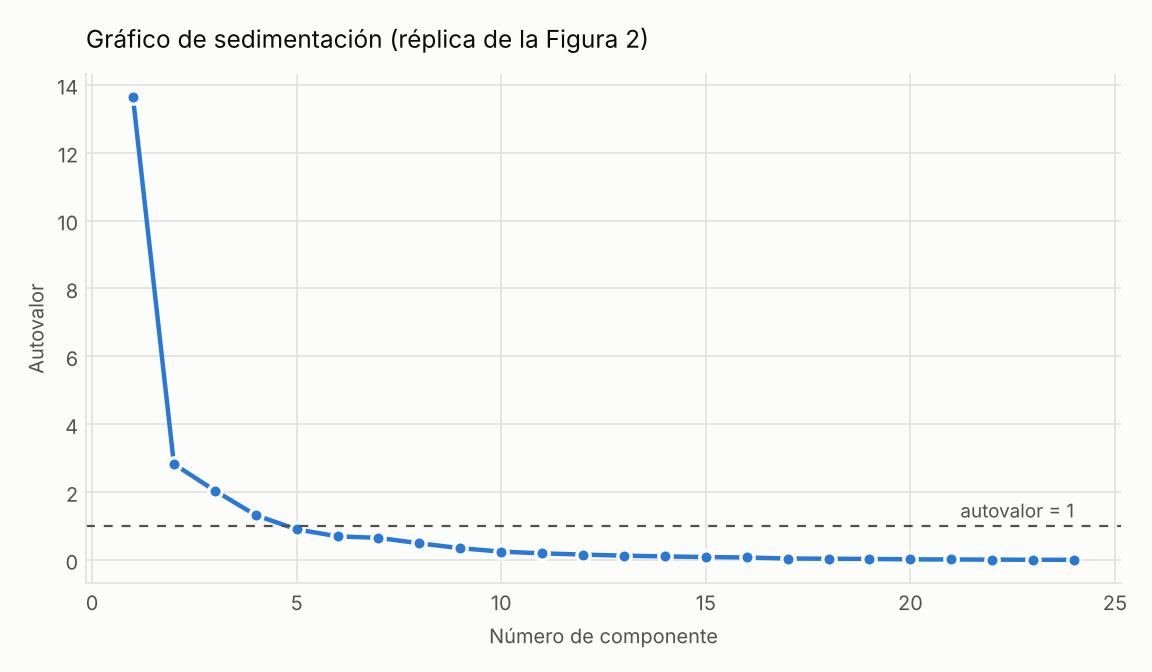

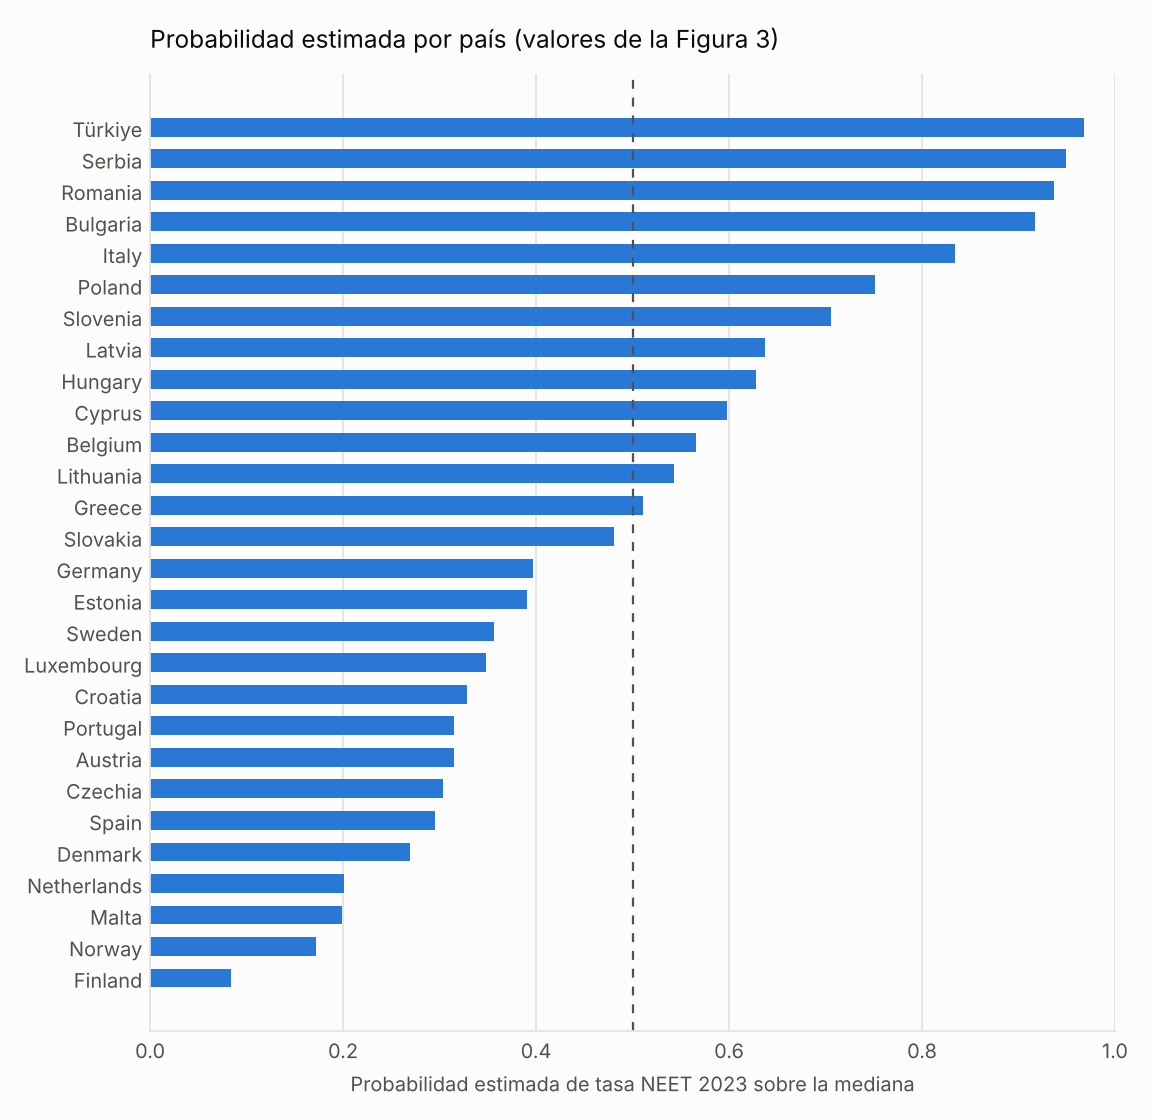

In [23]:
from IPython.display import Image, display
figuras(pca, diag)
display(Image(g("fig_sedimentacion.png"), width=650)); display(Image(g("fig_probabilidad_por_pais.png"), width=650))

## Resumen: réplica frente al paper
Cada cifra publicada se compara con la réplica, con tolerancia de medio decimal del último dígito que publica el paper.

In [24]:
r = pd.DataFrame(RESUMEN)
r.to_csv(os.path.join(AQUI, "resumen_replica_vs_paper.csv"), index=False)
tabla = r.groupby("análisis", sort=False)["coincide"].agg(comparaciones="size", coinciden=lambda s: (s == "sí").sum())
tabla["no coinciden"] = tabla["comparaciones"] - tabla["coinciden"]
tabla.to_csv(os.path.join(AQUI, "resumen_por_analisis.csv"))
print(f"Total: {len(r)} cifras comparadas; coinciden {(r['coincide'] == 'sí').sum()}; no coinciden {(r['coincide'] == 'NO').sum()}")
tabla

Total: 420 cifras comparadas; coinciden 412; no coinciden 8


,comparaciones,coinciden,no coinciden
análisis,,,
1. Descriptivos (Tabla A2),140,140,0
2. Normalidad (Tabla 2),112,110,2
"3. Spearman (texto, sección 5.1)",5,0,5
4. PCA (sección 5.2),3,3,0
4. PCA: autovalores (Tabla A3),24,24,0
4. PCA: matriz rotada Varimax (Tabla A4),96,96,0
4. PCA: correlación entre componentes Promax (Tabla 3),6,6,0
4. PCA: sumas de cuadrados rotadas (Tabla A3),4,4,0
5. Regresión logística (sección 5.3),7,7,0


In [25]:
r[r["coincide"] == "NO"]

,análisis,indicador,paper,réplica,coincide
161,2. Normalidad (Tabla 2),2020CHAT1: K-S sig.,0.1370,0.1443,NO
245,2. Normalidad (Tabla 2),I_DSK2_2023_LM: K-S sig.,0.1350,0.1424,NO
252,"3. Spearman (texto, sección 5.1)",redes sociales 2020 (año más cercano: NEET2020),0.4120,-0.3762,NO
253,"3. Spearman (texto, sección 5.1)",mensajería 2021 (año más cercano: NEET2020),0.3670,-0.0397,NO
254,"3. Spearman (texto, sección 5.1)",protección de datos 2023 (año más cercano: NEE...,-0.5020,-0.5338,NO
255,"3. Spearman (texto, sección 5.1)",habilidades bajas 2021 (año más cercano: NEET2...,0.4780,0.4052,NO
256,"3. Spearman (texto, sección 5.1)",sin habilidades 2023 (año más cercano: NEET2023),0.5360,0.2775,NO
419,7. Árbol CHAID: validación cruzada (depende de...,riesgo (réplica = mediana de 1000 sorteos),0.2860,0.4286,NO
